# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** Amit Shukla
**Roll Number:** AP24110011320
**Date:** 09-10-2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [2]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:* A 70/30 split has higher entropy than a 90/10 split. This makes sense because a 90/10 split is much more pure (easier to guess the label), whereas a 70/30 split is closer to a 50/50 split (more mixed, making it harder to guess the label).

### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [3]:
# Entropy of parent (8 Yes, 6 No)
parent_counts = [8, 6]
parent_entropy = entropy(parent_counts)
print("Parent Entropy:", round(parent_entropy, 4))

# Children counts
left_counts = [6, 0]
right_counts = [2, 6]

# Entropy of children
left_entropy = entropy(left_counts)
right_entropy = entropy(right_counts)

# Total samples
total_samples = sum(parent_counts)
left_weight = sum(left_counts) / total_samples
right_weight = sum(right_counts) / total_samples

# Weighted average entropy of children
weighted_avg_entropy = left_weight * left_entropy + right_weight * right_entropy

# Information Gain
info_gain_split = parent_entropy - weighted_avg_entropy
print("Information Gain:", round(info_gain_split, 4))


Parent Entropy: 0.9852
Information Gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [4]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [5]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [6]:
# 1. Compute Information Gain for attributes
gain_outlook = info_gain(tennis, 'Outlook')
gain_temperature = info_gain(tennis, 'Temperature')
gain_humidity = info_gain(tennis, 'Humidity')

print('Gain(Outlook):', round(gain_outlook, 4))
print('Gain(Temperature):', round(gain_temperature, 4))
print('Gain(Humidity):', round(gain_humidity, 4))

# 2. Which attribute does ID3 pick as the root?
print("\nID3 picks 'Outlook' as the root since it has the highest information gain.")

# 3. For the root's branch that is not pure, which attribute would you split on next?
sunny_branch = tennis[tennis['Outlook'] == 'Sunny']
print("\n--- Sunny Branch ---")
print("Gain(Temperature):", round(info_gain(sunny_branch, 'Temperature'), 4))
print("Gain(Humidity):", round(info_gain(sunny_branch, 'Humidity'), 4))
print("Gain(Wind):", round(info_gain(sunny_branch, 'Wind'), 4))
print("-> For the Sunny branch, ID3 would split on 'Humidity' next.")


Gain(Outlook): 0.2467
Gain(Temperature): 0.0292
Gain(Humidity): 0.1518

ID3 picks 'Outlook' as the root since it has the highest information gain.

--- Sunny Branch ---
Gain(Temperature): 0.571
Gain(Humidity): 0.971
Gain(Wind): 0.02
-> For the Sunny branch, ID3 would split on 'Humidity' next.


**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:* An `Overcast` branch is pure (all samples belong to one class). Once a branch is pure, the entropy is 0, meaning there is no more uncertainty in the labels. Splitting it further cannot yield any more information gain, so it becomes a leaf node immediately.

## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


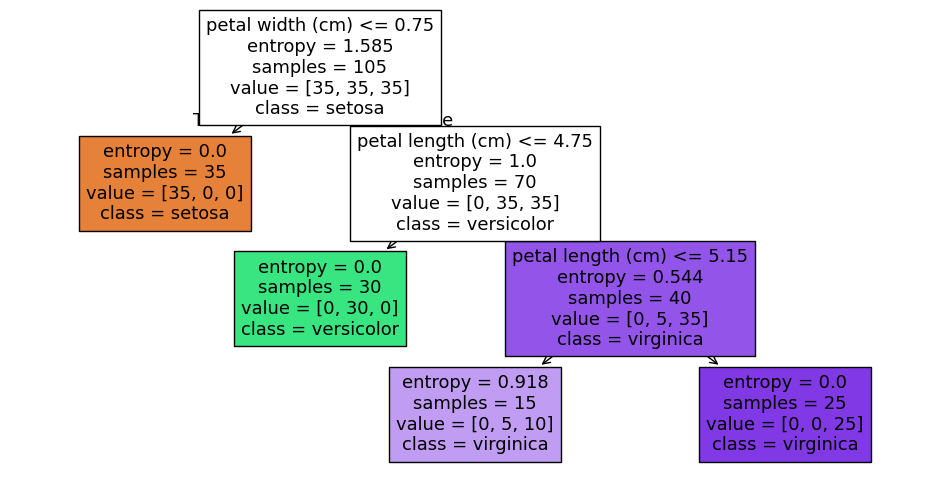

In [7]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


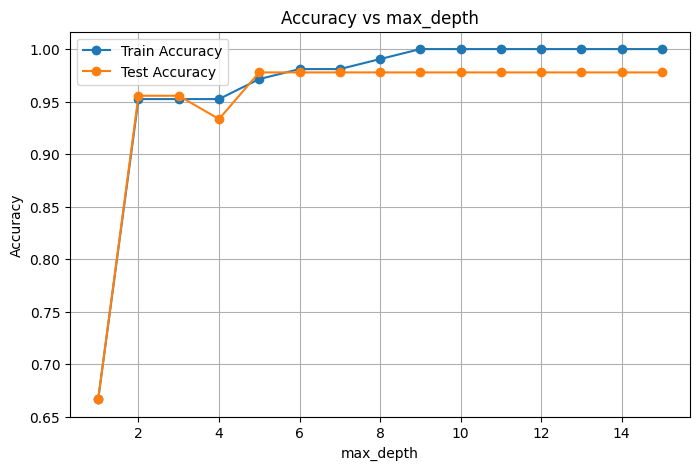

Depth with best test accuracy: 5


In [8]:
depths = range(1, 16)
train_accs = []
test_accs = []

for d in depths:
    t = DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=1)
    t.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, t.predict(X_train)))
    test_accs.append(accuracy_score(y_test, t.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_accs, label='Train Accuracy', marker='o')
plt.plot(depths, test_accs, label='Test Accuracy', marker='o')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Accuracy vs max_depth')
plt.legend()
plt.grid(True)
plt.show()

best_depth = depths[np.argmax(test_accs)]
print("Depth with best test accuracy:", best_depth)


**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:* In Week 6, the polynomial degree played this role. In Week 7, it was $K$ (number of neighbors) in KNN. At the extreme of low max_depth (like low degree or high $K$), the model underfits the data (high bias). At the extreme of high max_depth (like high degree or low $K$), the model overfits, memorizing the training data perfectly but generalizing poorly to unseen data.

# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [9]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


Unscaled Tree test accuracy: 0.8814814814814815
Depth 3 test accuracy: 0.5296296296296297
Depth 6 test accuracy: 0.8537037037037037
Depth 10 test accuracy: 0.8796296296296297


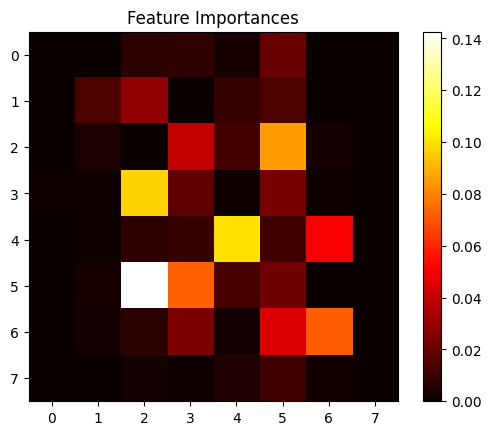

In [10]:
# 1. Fit unscaled tree
tree_digits = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree_digits.fit(Xd_train, yd_train)
# Note: No scaling is needed for trees because they only test features against single threshold values one by one.
print("Unscaled Tree test accuracy:", accuracy_score(yd_test, tree_digits.predict(Xd_test)))

# 2. Max depth sweep
for d in [3, 6, 10]:
    t = DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=1)
    t.fit(Xd_train, yd_train)
    print(f"Depth {d} test accuracy:", accuracy_score(yd_test, t.predict(Xd_test)))

# 3. Feature importance
importances = tree_digits.feature_importances_.reshape(8, 8)
plt.imshow(importances, cmap='hot')
plt.title("Feature Importances")
plt.colorbar()
plt.show()


**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:* The tree is less accurate than KNN on digits. The importance map shows that the decision tree splits based on very specific individual pixels (hot spots). This makes it highly brittle and sensitive to small variations or shifts in handwriting. In contrast, KNN considers the whole image holistically by measuring overall distance.

# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [11]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [12]:
from sklearn.tree import export_text

# 1. Fit tree
tree_text = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree_text.fit(X_text, labels)

# 2. Print tree
print(export_text(tree_text, feature_names=vocab))

# 3. Predict topics
new_sentence = 'the striker scored a goal'
ambiguous_sentence = 'add salt to the new phone'

X_new = np.array([to_vector(new_sentence, vocab), to_vector(ambiguous_sentence, vocab)])
predictions = tree_text.predict(X_new)
print(f"Prediction for '{new_sentence}':", predictions[0])
print(f"Prediction for '{ambiguous_sentence}':", predictions[1])


|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking

Prediction for 'the striker scored a goal': sports
Prediction for 'add salt to the new phone': sports


**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:* If more sentences were added, the tree would likely choose completely different split words as the vocabulary grows. Trusting a tree trained on very little data is risky because it simply memorizes the few arbitrary words that perfectly separate the tiny training set. It lacks robustness and will not generalize well to unseen text.

## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
